# CMPT 459 Project: EDA Notebook
**Predicting High-Impact Traffic Accidents (US Accidents 2016-2023)**

Team: *(add names here)*

**How to use this notebook**
- Every section below has an **Owner** line. Put your name there once the team agrees on the split.
- Code cells are a working starter. Extend or replace them in your own section.
- Each section ends with a **Notes** cell. Write these in your own words after you look at your actual plots (the guidelines don't allow LLM-written prose).
- Do not clear outputs before committing. The notebook must run top-to-bottom with *Restart & Run All* and no edits.

---
## 0. Setup and configuration
**Owner:** _TBD_  |  **Tasks:** shared imports, config, and data loading. Everyone depends on this, so change it only through a PR.

In [1]:
import os, sys, glob, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

SAMPLE_FILE = "US_Accidents_March23_sampled_500k.csv"
KAGGLE_SLUG = "sobhanmoosavi/us-accidents"

In [2]:
def _find_csvs(folder):
    return sorted(glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True))

def find_or_download_csv():
    """Return (path, is_sample). Tries: local/Kaggle input -> kagglehub single file ->
    forced fresh download -> whole dataset folder (sample by name, else the full CSV)."""
    # 1) already on disk (Kaggle notebook input, local data/ folder, current folder)
    local = [f"/kaggle/input/us-accidents/{SAMPLE_FILE}", os.path.join("data", SAMPLE_FILE), SAMPLE_FILE]
    for p in local:
        if os.path.exists(p):
            return p, True
    hits = glob.glob(f"/kaggle/input/**/*sampled*500k*.csv", recursive=True)
    if hits:
        return hits[0], True

    try:
        import kagglehub
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub

    # 2) download just the sample file (retry once with a forced refresh: Colab's cache can be stale)
    for force in (False, True):
        try:
            return kagglehub.dataset_download(KAGGLE_SLUG, path=SAMPLE_FILE, force_download=force), True
        except Exception as e:
            print(f"[single-file download failed (force_download={force})]: {type(e).__name__}: {e}")

    # 3) download the whole dataset folder and look at what is really in it
    folder = kagglehub.dataset_download(KAGGLE_SLUG, force_download=True)
    csvs = _find_csvs(folder)
    print("CSV files found in dataset folder:", [os.path.basename(c) for c in csvs])
    sampled = [c for c in csvs if "sampled" in os.path.basename(c).lower() or "500k" in os.path.basename(c).lower()]
    if sampled:
        return sampled[0], True
    if csvs:                                   # fall back to the full file; we sample it below
        return max(csvs, key=os.path.getsize), False
    raise FileNotFoundError("No CSV found in the Kaggle dataset download.")

def load_data(path, is_sample, n_target=500_000, full_rows=7_728_394):
    """Load the 500k sample. If we only have the full file, draw a reproducible ~500k random sample from it in chunks."""
    if is_sample:
        return pd.read_csv(path)
    print("Full file found instead of the sample: drawing a reproducible ~500k random sample (takes a few minutes)...")
    frac = n_target / full_rows
    parts = [c.sample(frac=frac, random_state=RANDOM_SEED)
             for c in pd.read_csv(path, chunksize=500_000)]
    return pd.concat(parts, ignore_index=True)

DATA_PATH, IS_SAMPLE = find_or_download_csv()
print("Loading:", DATA_PATH)
df_raw = load_data(DATA_PATH, IS_SAMPLE)
print("Loaded shape:", df_raw.shape)


[single-file download failed (force_download=False)]: KaggleApiHTTPError: 404 Client Error.

Resource not found at URL: https://kaggle.com/datasets/sobhanmoosavi/us-accidents/versions/13
Please make sure you specified the correct resource identifiers.
[single-file download failed (force_download=True)]: KaggleApiHTTPError: 404 Client Error.

Resource not found at URL: https://kaggle.com/datasets/sobhanmoosavi/us-accidents/versions/13
Please make sure you specified the correct resource identifiers.


100%|██████████| 653M/653M [00:07<00:00, 96.0MB/s] 

Extracting files...


CSV files found in dataset folder: ['US_Accidents_March23.csv']
Loading: C:\Users\yerki\.cache\kagglehub\datasets\sobhanmoosavi\us-accidents\versions\13\US_Accidents_March23.csv
Full file found instead of the sample: drawing a reproducible ~500k random sample (takes a few minutes)...
Loaded shape: (499996, 46)


In [3]:
# ---- Shared feature configuration (final feature list) ----
TARGET_COL = "Severity"

NUMERIC_FEATURES     = ["Start_Lat", "Start_Lng", "Temperature(F)", "Humidity(%)", "Pressure(in)",
                        "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
CATEGORICAL_FEATURES = ["Weather_Condition", "Sunrise_Sunset"]
BOOLEAN_FEATURES     = ["Amenity", "Crossing", "Junction", "Railway", "Station", "Stop", "Traffic_Signal"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BOOLEAN_FEATURES      # 17 raw model features

# Start_Time is not used raw; it is transformed into these model features (year is deliberately NOT one of them)
DERIVED_TIME_FEATURES = ["hour", "dayofweek", "month", "is_weekend", "rush_hour"]
MODEL_FEATURES = FEATURES + DERIVED_TIME_FEATURES

# Looked at in EDA only, NOT used for modelling:
LEAKAGE_FEATURES = ["End_Time"]           # only known after the accident clears (target is delay)
LOW_VARIANCE_FEATURES = ["Roundabout", "Turning_Loop", "Bump", "Traffic_Calming", "No_Exit", "Give_Way"]  # ~constant
RAW_SELECTED = FEATURES + ["Start_Time"] + LEAKAGE_FEATURES + LOW_VARIANCE_FEATURES

# Other columns excluded from modelling: post-accident info (End_Lat/Lng, Distance, Description),
# heavy missingness (Wind_Chill), or not useful (Weather_Timestamp). Source is for diagnostics only.
OTHER_EXCLUDED_COLS = ["End_Lat", "End_Lng", "Distance(mi)", "Description", "Wind_Chill(F)", "Weather_Timestamp", "Source"]

print(f"{len(FEATURES)} raw model features + Start_Time -> {len(MODEL_FEATURES)} model features after time transformation")
print(f"{len(RAW_SELECTED)} raw columns examined in this notebook (incl. EDA-only ones)")
missing_cols = [c for c in RAW_SELECTED + [TARGET_COL] if c not in df_raw.columns]
assert not missing_cols, f"Columns not found in data: {missing_cols}"

17 raw model features + Start_Time -> 22 model features after time transformation
25 raw columns examined in this notebook (incl. EDA-only ones)


---
## 1. Data loading and overview
**Owner:** _TBD_

**Tasks**
- Shape, dtypes, memory usage, `head()`, summary statistics.
- Time span of the data (min/max `Start_Time`).
- Table of the selected features and the role of each (model feature, transformed, EDA only).

In [4]:
df = df_raw.copy()
for c in ["Start_Time", "End_Time"]:
    df[c] = pd.to_datetime(df[c], errors="coerce", format="mixed")

print("Rows, columns:", df.shape)
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print("Time span:", df["Start_Time"].min(), "->", df["Start_Time"].max())
df.head()

Rows, columns: (499996, 46)
Memory: 596.8 MB
Time span: 2016-02-08 07:59:35 -> 2023-03-31 22:59:30


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-104248,Source2,2,2016-04-25 17:18:11,2016-04-25 18:18:11,33.939304,-117.218231,NaN,NaN,0.01,Right hand shoulder blocked due to accident on...,CA-60 W,Moreno Valley,Riverside,CA,92553,US,US/Pacific,KRIV,2016-04-25 16:58:00,63.9,NaN,29.0,29.80,10.0,West,11.5,NaN,Clear,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
1,A-199683,Source2,2,2017-01-10 09:40:16,2017-01-10 10:10:02,42.549671,-71.847313,NaN,NaN,0.01,Accident on MA-2 Eastbound before MA-31 Prince...,MA-2 E,Fitchburg,Worcester,MA,01420,US,US/Eastern,KFIT,2017-01-10 09:52:00,19.0,13.9,71.0,30.66,10.0,SSW,3.5,NaN,Clear,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
2,A-140206,Source2,3,2016-09-02 17:27:56,2016-09-02 18:27:56,26.203491,-80.143852,NaN,NaN,0.00,Center lane blocked due to accident on I-95 No...,NE 62nd St,Fort Lauderdale,Broward,FL,33334,US,US/Eastern,KFXE,2016-09-02 17:53:00,91.0,NaN,48.0,29.99,10.0,SW,12.7,NaN,Clear,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
3,A-132821,Source2,2,2016-09-29 18:07:37,2016-09-29 18:51:28,27.440348,-82.575432,NaN,NaN,0.00,Left lane blocked due to accident on US-41 14t...,14th St W,Bradenton,Manatee,FL,34207-3610,US,US/Eastern,KSRQ,2016-09-29 18:05:00,77.0,NaN,88.0,30.02,1.5,Variable,3.5,0.08,Heavy Thunderstorms and Rain,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day
4,A-408710,Source2,3,2017-05-03 12:12:18,2017-05-03 12:44:00,33.901752,-118.370316,NaN,NaN,0.01,Multi-vehicle accident on I-405 Northbound at ...,W Rosecrans Ave,Hawthorne,Los Angeles,CA,90250,US,US/Pacific,KHHR,2017-05-03 11:53:00,72.0,NaN,61.0,29.96,10.0,WSW,8.1,NaN,Clear,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day


In [5]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "example": df.iloc[0],
})
overview

,dtype,n_unique,example
ID,str,499996,A-104248
Source,str,3,Source2
Severity,int64,4,2
Start_Time,datetime64[ns],482175,2016-04-25 17:18:11
End_Time,datetime64[ns],491639,2016-04-25 18:18:11
Start_Lat,float64,370436,33.939304
Start_Lng,float64,371434,-117.218231
End_Lat,float64,220491,NaN
End_Lng,float64,221595,NaN
Distance(mi),float64,10691,0.01


In [6]:
df[NUMERIC_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
Start_Lat,499996.0,36.212602,5.071976,24.555269,33.411053,35.835129,40.088727,49.000560
Start_Lng,499996.0,-94.707786,17.391256,-124.548074,-117.221464,-87.768452,-80.357706,-67.553307
Temperature(F),489386.0,61.652195,19.016246,-89.000000,49.000000,64.000000,76.000000,172.000000
Humidity(%),488718.0,64.863259,22.808652,1.000000,48.000000,67.000000,84.000000,100.000000
Pressure(in),490944.0,29.538732,1.002753,0.300000,29.370000,29.860000,30.030000,39.450000
Visibility(mi),488515.0,9.091196,2.703783,0.000000,10.000000,10.000000,10.000000,100.000000
Wind_Speed(mph),463042.0,7.680385,5.295212,0.000000,4.600000,7.000000,10.400000,243.000000
Precipitation(in),357162.0,0.008062,0.088623,0.000000,0.000000,0.000000,0.000000,10.160000


In [7]:
roles = (
    [(c, "numeric", "model feature") for c in NUMERIC_FEATURES]
    + [(c, "categorical", "model feature") for c in CATEGORICAL_FEATURES]
    + [(c, "boolean", "model feature") for c in BOOLEAN_FEATURES]
    + [("Start_Time", "datetime", "transformed into hour/day/month/weekend/rush-hour")]
    + [(c, "datetime", "EDA only (leakage: known after the accident)") for c in LEAKAGE_FEATURES]
    + [(c, "boolean", "EDA only (near-constant)") for c in LOW_VARIANCE_FEATURES]
)
feature_table = pd.DataFrame(roles, columns=["feature", "type", "role"])
print("Other columns excluded from modelling:", OTHER_EXCLUDED_COLS)
feature_table

Other columns excluded from modelling: ['End_Lat', 'End_Lng', 'Distance(mi)', 'Description', 'Wind_Chill(F)', 'Weather_Timestamp', 'Source']


,feature,type,role
0,Start_Lat,numeric,model feature
1,Start_Lng,numeric,model feature
2,Temperature(F),numeric,model feature
3,Humidity(%),numeric,model feature
4,Pressure(in),numeric,model feature
5,Visibility(mi),numeric,model feature
6,Wind_Speed(mph),numeric,model feature
7,Precipitation(in),numeric,model feature
8,Weather_Condition,categorical,model feature
9,Sunrise_Sunset,categorical,model feature


**Notes (write in your own words):**

- 

---
## 2. Target definition and class balance
**Owner:** _TBD_

**Tasks**
- Convert `Severity` to binary: **1 = severity 4 (high impact)**, 0 = severity 1-3.
- Class counts and percentages, original 4-level distribution plus the binary one.
- How the positive-class rate changes by year (the proposal flags this as a challenge).
- Derive time features from `Start_Time` (hour, day of week, month, weekend flag, rush-hour flag; year is for EDA only).
- Accident duration (`End_Time` - `Start_Time`) by severity, as evidence for why severity 4 = long delay. EDA only.

Original severity counts:
 Severity
1      4387
2    398309
3     84028
4     13272
Name: count, dtype: int64 

Binary target counts:
 target
0    486724
1     13272
Name: count, dtype: int64

Positive class (severity 4): 2.65%


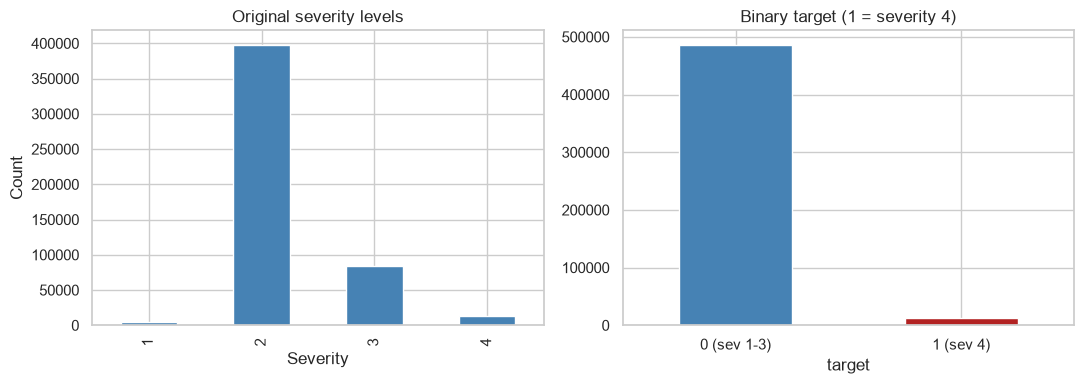

In [8]:
df["target"] = (df[TARGET_COL] == 4).astype(int)

df["hour"] = df["Start_Time"].dt.hour
df["dayofweek"] = df["Start_Time"].dt.dayofweek      # 0 = Monday
df["month"] = df["Start_Time"].dt.month
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
df["rush_hour"] = ((df["dayofweek"] < 5) & (df["hour"].between(7, 9) | df["hour"].between(16, 18))).astype(int)
df["year"] = df["Start_Time"].dt.year                # EDA only, not a model feature

orig = df[TARGET_COL].value_counts().sort_index()
binary = df["target"].value_counts().sort_index()
print("Original severity counts:\n", orig, "\n")
print("Binary target counts:\n", binary)
print(f"\nPositive class (severity 4): {df['target'].mean() * 100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
orig.plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Original severity levels"); axes[0].set_xlabel("Severity"); axes[0].set_ylabel("Count")
binary.plot(kind="bar", ax=axes[1], color=["steelblue", "firebrick"])
axes[1].set_title("Binary target (1 = severity 4)"); axes[1].set_xticklabels(["0 (sev 1-3)", "1 (sev 4)"], rotation=0)
plt.tight_layout(); plt.show()

,positive_rate,n_positive,n_total
year,,,
2016,0.036184,963,26614
2017,0.034708,1613,46474
2018,0.028579,1653,57840
2019,0.029638,1827,61643
2020,0.026328,2007,76232
2021,0.019912,2015,101196
2022,0.023974,2733,113997
2023,0.028813,461,16000


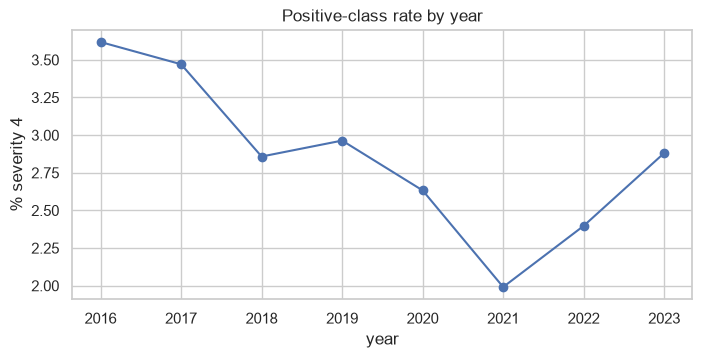

In [9]:
by_year = df.groupby("year")["target"].agg(["mean", "sum", "count"])
by_year.columns = ["positive_rate", "n_positive", "n_total"]
display(by_year)

ax = (by_year["positive_rate"] * 100).plot(marker="o", figsize=(8, 3.5))
ax.set_ylabel("% severity 4"); ax.set_title("Positive-class rate by year"); plt.show()

Rows with non-positive duration: 0


,count,mean,std,min,25%,50%,75%,max
Severity,,,,,,,,
1,4387.0,45.7,35.9,15.0,29.7,44.7,59.8,1640.0
2,398309.0,497.8,14177.0,4.0,44.4,77.5,129.2,1576859.7
3,84028.0,73.0,999.3,9.6,29.6,44.4,60.0,280505.6
4,13272.0,1605.5,27463.7,10.9,65.0,131.2,360.0,1298444.6


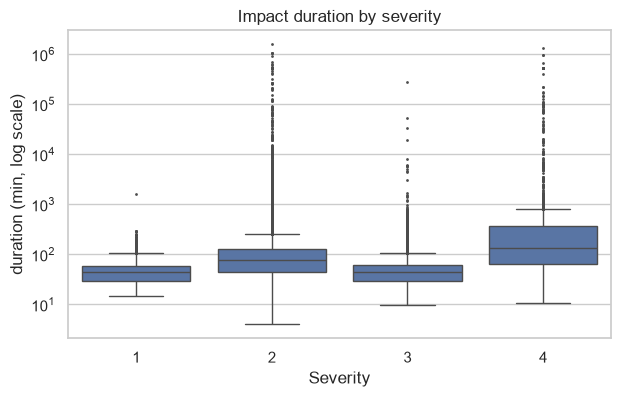

In [10]:
# Duration is EDA ONLY: End_Time is not known at report time, so it must not be a model feature.
df["duration_min"] = (df["End_Time"] - df["Start_Time"]).dt.total_seconds() / 60
print("Rows with non-positive duration:", (df["duration_min"] <= 0).sum())
valid = df[df["duration_min"] > 0]
display(valid.groupby(TARGET_COL)["duration_min"].describe().round(1))

plt.figure(figsize=(7, 4))
sns.boxplot(data=valid, x=TARGET_COL, y="duration_min", flierprops={"markersize": 1})
plt.yscale("log"); plt.ylabel("duration (min, log scale)"); plt.title("Impact duration by severity")
plt.show()

**Notes (write in your own words):**

- 

---
## 3. Data quality: missingness, duplicates, constant and high-cardinality columns
**Owner:** Duplicates and Constants Yerkin Boranbayev

**Tasks**
- Missing values per column (table plus bar chart), and per row among the selected features.
- Duplicate rows and duplicate IDs.
- Constant or near-constant columns, and high-cardinality categoricals.
- Brief note per issue on how we plan to handle it (imputation, drop, etc.). Handling itself happens in the preprocessing deliverable.

,n_missing,pct_missing
End_Lng,220112,44.022752
End_Lat,220112,44.022752
Precipitation(in),142834,28.567029
Wind_Chill(F),129690,25.938208
Wind_Speed(mph),36954,7.390859
Visibility(mi),11481,2.296218
Wind_Direction,11443,2.288618
Humidity(%),11278,2.255618
Weather_Condition,11273,2.254618
Temperature(F),10610,2.122017


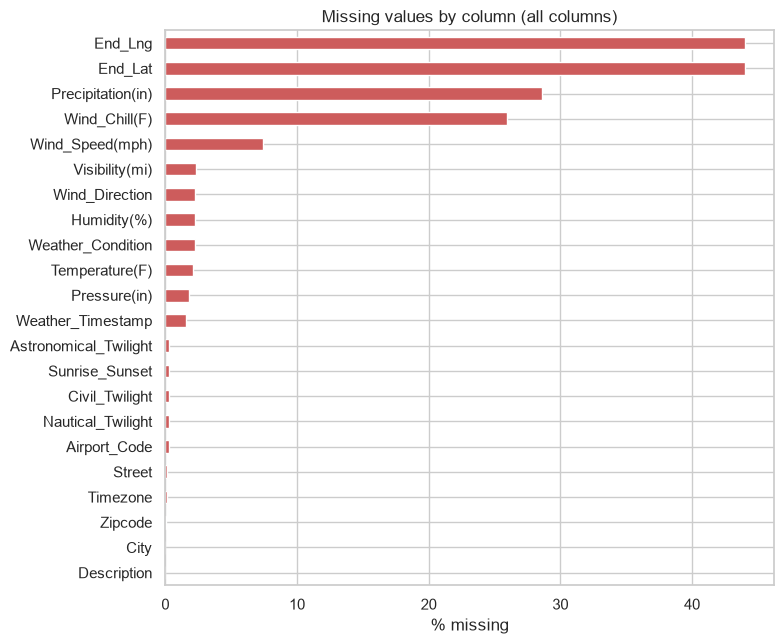

In [11]:
miss = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": df.isna().mean() * 100,
}).sort_values("pct_missing", ascending=False)
miss = miss[miss["n_missing"] > 0]
display(miss)

if len(miss):
    ax = miss["pct_missing"].plot(kind="barh", figsize=(8, max(3, 0.3 * len(miss))), color="indianred")
    ax.invert_yaxis(); ax.set_xlabel("% missing"); ax.set_title("Missing values by column (all columns)")
    plt.tight_layout(); plt.show()

Selected-feature rows with >= 1 missing value: 30.6%
Selected-feature rows with >= 3 missing values: 2.2%


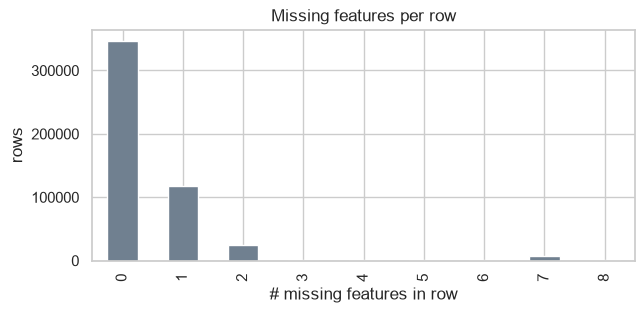

In [12]:
row_missing = df[FEATURES].isna().sum(axis=1)
print("Selected-feature rows with >= 1 missing value:", f"{(row_missing > 0).mean() * 100:.1f}%")
print("Selected-feature rows with >= 3 missing values:", f"{(row_missing >= 3).mean() * 100:.1f}%")
row_missing.value_counts().sort_index().plot(kind="bar", figsize=(7, 3), color="slategray")
plt.xlabel("# missing features in row"); plt.ylabel("rows"); plt.title("Missing features per row"); plt.show()

In [13]:
id_dups = df["ID"].duplicated().sum() if "ID" in df.columns else "n/a"
full_dups = df.drop(columns=["ID"], errors="ignore").duplicated().sum()
feat_dups = df.duplicated(subset=FEATURES + ["Start_Time"]).sum()
print("Duplicate IDs:", id_dups)
print("Fully duplicated rows (ignoring ID):", full_dups)
print("Duplicates on selected features + Start_Time:", feat_dups)

Duplicate IDs: 0
Fully duplicated rows (ignoring ID): 509
Duplicates on selected features + Start_Time: 3210


### Note:
- There are no duplicate id in our records
- There are 509 same rows of data (if we ignore ID). Since, number of fully similar rows are limited we can just ignore them.
- There are 3210 duplicates rows with same Start_Time and with subset of selected features. It is still negligeble number in comparison with our requirement of 50,000 records. We are still have over 400,000 records in our dataset.

In [39]:
card = pd.DataFrame({"n_unique": df.nunique(), "dtype": df.dtypes.astype(str)})
card["pct_unique"] = card["n_unique"] / len(df) * 100
print("Constant columns:", card[card["n_unique"] <= 1].index.tolist())
print("\nHigh-cardinality object columns (> 1000 unique):")
display(card[(card["dtype"] == "object") & (card["n_unique"] > 1000)].sort_values("n_unique", ascending=False))
print("Cardinality of selected categoricals:")
display(card.loc[CATEGORICAL_FEATURES])

Constant columns: ['Country', 'Turning_Loop']

High-cardinality object columns (> 1000 unique):


,n_unique,dtype,pct_unique


Cardinality of selected categoricals:


,n_unique,dtype,pct_unique
Weather_Condition,108,str,0.0216
Sunrise_Sunset,2,str,0.0004


### Note
- We have two constant columns: Country and Turning_Loop. These columns no information and model cannot learn anything from them so they are safe to drop.
- There are no extremely high cardinality objects (>1000 unique categories). Highest cardinality feature is Weather Condition, which is 108. Grouping should be applied for weather condition

In [15]:
# Near-constant check on all POI-style boolean columns
poi_cols = BOOLEAN_FEATURES + LOW_VARIANCE_FEATURES
dominant = pd.DataFrame({
    "pct_dominant_value": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in poi_cols],
    "n_minority_rows": [df[c].value_counts().iloc[1:].sum() for c in poi_cols],
    "role": ["model feature"] * len(BOOLEAN_FEATURES) + ["EDA only (near-constant)"] * len(LOW_VARIANCE_FEATURES),
}, index=poi_cols).sort_values("pct_dominant_value", ascending=False).round(2)
dominant

,pct_dominant_value,n_minority_rows,role
Turning_Loop,100.00,0,EDA only (near-constant)
Roundabout,100.00,15,EDA only (near-constant)
Bump,99.96,216,EDA only (near-constant)
Traffic_Calming,99.90,491,EDA only (near-constant)
No_Exit,99.74,1278,EDA only (near-constant)
Give_Way,99.52,2388,EDA only (near-constant)
Railway,99.13,4329,model feature
Amenity,98.73,6327,model feature
Station,97.37,13151,model feature
Stop,97.22,13880,model feature


### Note:
- We have 6 near constant columns that might which we would drop. They have small amount of information for us since they have almost no accidents and have little help with severity prediction.

In [16]:
# Does missingness depend on severity? (e.g. is a missing Precipitation value informative?)
check_cols = ["Precipitation(in)", "Wind_Speed(mph)", "Visibility(mi)", "Weather_Condition", "End_Lat", "Wind_Chill(F)"]
miss_by_sev = pd.DataFrame({c: df[c].isna().groupby(df[TARGET_COL]).mean() * 100 for c in check_cols}).round(2)
miss_by_sev.index.name = "Severity"
print("% missing by original severity level:")
miss_by_sev

% missing by original severity level:


,Precipitation(in),Wind_Speed(mph),Visibility(mi),Weather_Condition,End_Lat,Wind_Chill(F)
Severity,,,,,,
1,5.54,1.87,1.14,1.28,57.15,3.15
2,24.22,6.50,2.26,2.21,35.92,21.75
3,49.45,11.40,2.28,2.29,87.60,46.43
4,34.29,10.64,3.88,3.84,7.04,29.53


**Notes (write in your own words):** one bullet per issue found and what we plan to do about it.

- 

---
## 4. Distributions
**Owner:** Yerkin Boranbayev

**Tasks**
- Histograms of the numeric features and box plots split by target class.
- Counts for the categorical features (Weather_Condition has ~100 distinct values, so it will need grouping later) and the boolean road features.
- Severity-4 rate by hour, day of week, and month.
- Mention anything skewed, outlier-heavy, or visibly different between the two classes.

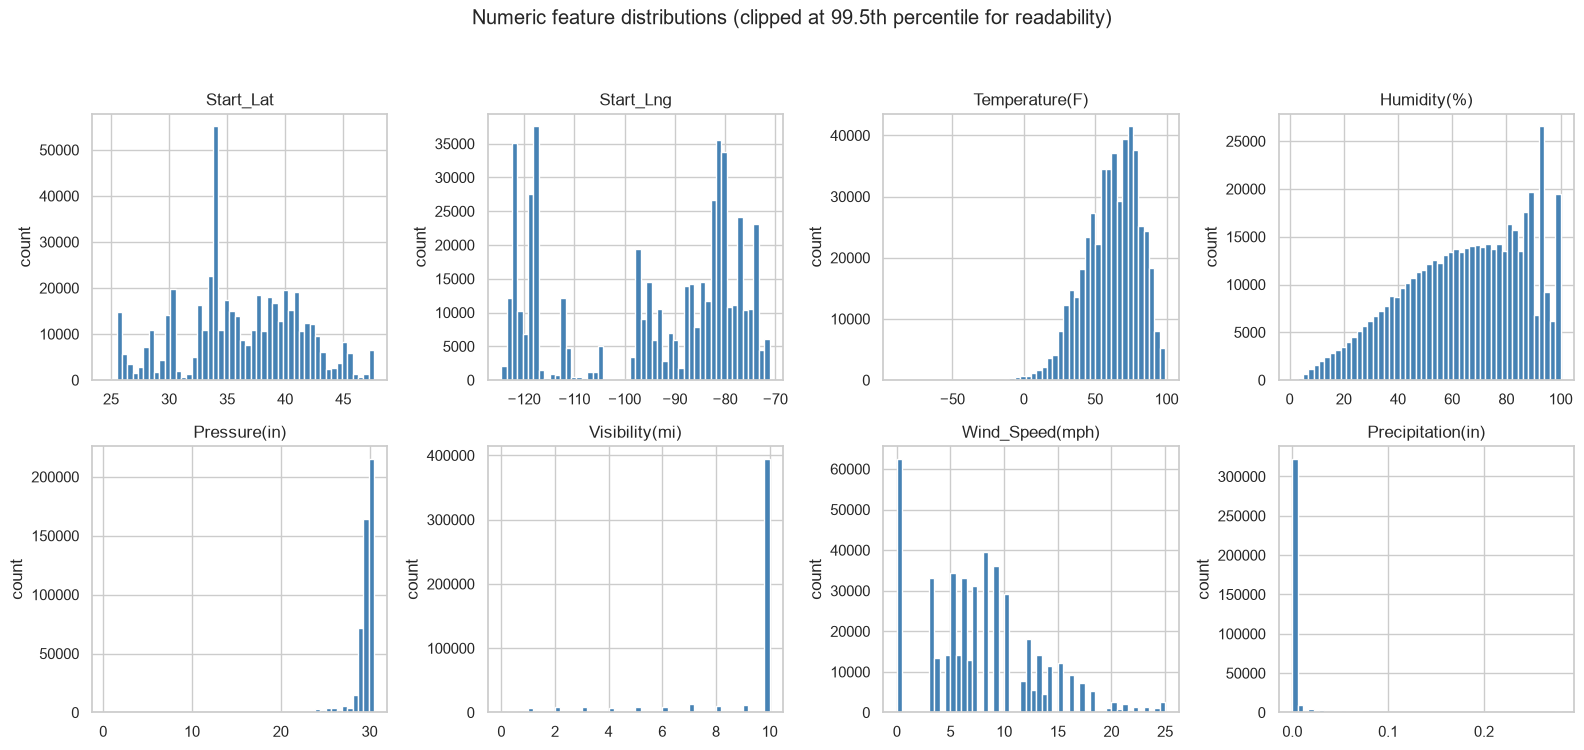

In [26]:
n_num = len(NUMERIC_FEATURES); ncols = 4; nrows = int(np.ceil(n_num / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.6 * nrows)); axes = axes.ravel()
for ax in axes[n_num:]: ax.axis("off")
for ax, col in zip(axes, NUMERIC_FEATURES):
    data = df[col].dropna()
    ax.hist(data.clip(upper=data.quantile(0.995)), bins=50, color="steelblue", edgecolor="white")
    ax.set_title(col); ax.set_ylabel("count")
fig.suptitle("Numeric feature distributions (clipped at 99.5th percentile for readability)", y=1.04)
plt.tight_layout(); plt.show()

### Note:
- Histograms illustrate how precipitation, visibility and pressure are piled up in one value.
- Precipitation has small tail and majority of accidents had no rain or snow at all.
- Visibility, absolute majority of accidents are recorded with 10 mile visibility which is maximum visibility. There are several smaller piles for all sorts of visibility measurements.
- Pressure, standard sea pressure is ~30. So, majority of records are measured around 30 is expected. Small tail with lower pressure indicates elevated location or weather condition.

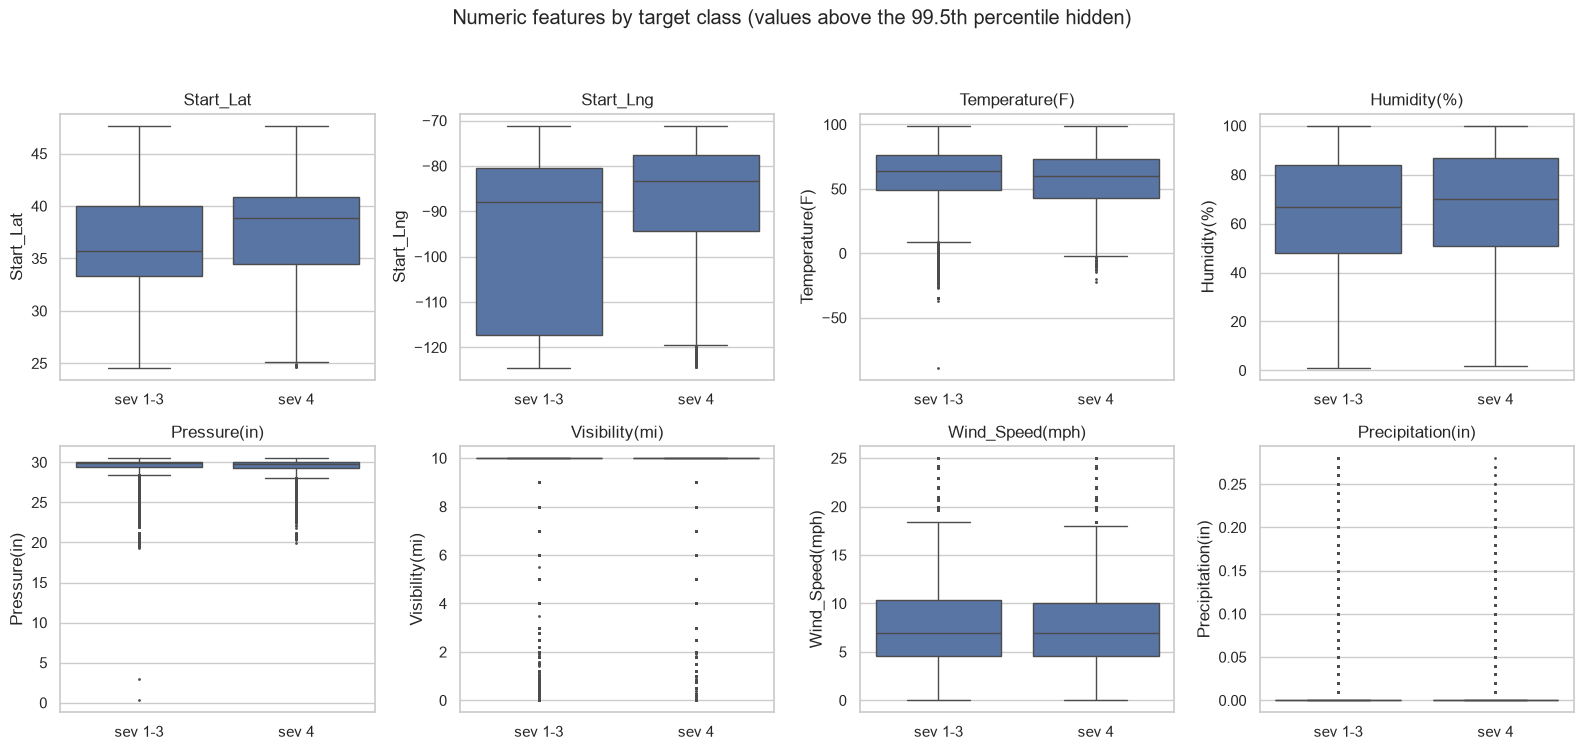

In [44]:
n_num = len(NUMERIC_FEATURES); ncols = 4; nrows = int(np.ceil(n_num / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.6 * nrows)); axes = axes.ravel()
for ax in axes[n_num:]: ax.axis("off")
for ax, col in zip(axes, NUMERIC_FEATURES):
    data = df[[col, "target"]].dropna()
    q = data[col].quantile(0.995)
    sns.boxplot(data=data[data[col] <= q], x="target", y=col, ax=ax, flierprops={"markersize": 1})
    ax.set_xticklabels(["sev 1-3", "sev 4"]); ax.set_xlabel(""); ax.set_title(col)
fig.suptitle("Numeric features by target class (values above the 99.5th percentile hidden)", y=1.04)
plt.tight_layout(); plt.show()

### Note:
- Latitude (sev 1-3) is slightly right skewed and box is not that wide indicating medium level of variety in values. Latitude for specifically severity 4 has slight left skew and similar variety of values. There are neglible number of outliers for severity 4 records.
- Longtitute (sev 1-3) is significantly left skewed and has huge value variety. Severity 4 longtitude is left skewed but in a lower degree and variety of values is significantly smaller. And for severity 4 there are some outliers.
- Temperature is roughly symmetrical for all severity levels. However, all records have significant number of outliers. Boxes are narrow, indicating smaller variety of values.
- Humidity is also roughly symmetrical for all severity levels and there are no outliers identified. Variety of values is medium.
- Pressure has very narrow box and also shows some outliers. There are slightly more outliers for sev 1-3.
- Visibility is collapsed box with majority of records having 10 mile visibility. All other values are indicated as outliers which is false.
- Wind speed for all severity levels have similarly right skewed medians. Variety of values is medium to narrow. There are significant number of outliers with high windspeed.
- Precipitation is another example with collapsed box with absolute majority of records having 0.00 precipitation. All other recorded cases are indicated as outliers which might not be true.

In [46]:
rows = []
for c in NUMERIC_FEATURES:
    s = df[c]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    out = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    rows.append({
        "feature": c,
        "skew": s.skew(),
        "pct_outlier_all": out.mean() * 100,
        "pct_outlier_sev4": out[df["target"] == 1].mean() * 100,
        "pct_outlier_rest": out[df["target"] == 0].mean() * 100,
        "median_sev4": s[df["target"] == 1].median(),
        "median_rest": s[df["target"] == 0].median(),
    })
outlier_summary = pd.DataFrame(rows).set_index("feature").round(2)
display(outlier_summary)

# Raw values: skew, extreme maxima, implausible values
summary = df[NUMERIC_FEATURES].agg(["min", "median", "mean", "max", "skew"]).T
summary["p99.9"] = df[NUMERIC_FEATURES].quantile(0.999)
summary["pct_zero"] = (df[NUMERIC_FEATURES] == 0).mean() * 100
display(summary.round(2))

ranges = {
    "Temperature(F)":    (-60, 130),
    "Humidity(%)":       (0, 100),
    "Pressure(in)":      (20, 32),
    "Visibility(mi)":    (0, 100),
    "Wind_Speed(mph)":   (0, 100),
    "Precipitation(in)": (0, 10),
    "Start_Lat":         (24, 50),
    "Start_Lng":         (-125, -66),
}
implausible = pd.DataFrame({
    "n_below": [(df[c] < lo).sum() for c, (lo, hi) in ranges.items()],
    "n_above": [(df[c] > hi).sum() for c, (lo, hi) in ranges.items()],
    "n_missing": [df[c].isna().sum() for c in ranges],
    "allowed_range": [f"{lo} to {hi}" for lo, hi in ranges.values()],
}, index=list(ranges))
display(implausible)

skewed = outlier_summary.index[outlier_summary["skew"] > 1].tolist()
skew_check = pd.DataFrame({
    "skew_raw": [df[c].skew() for c in skewed],
    "skew_log1p": [np.log1p(df[c].clip(lower=0)).skew() for c in skewed],
}, index=skewed).round(2)
display(skew_check)

,skew,pct_outlier_all,pct_outlier_sev4,pct_outlier_rest,median_sev4,median_rest
feature,,,,,,
Start_Lat,-0.07,0.00,0.00,0.00,38.90,35.78
Start_Lng,-0.48,0.00,0.00,0.00,-83.30,-87.92
Temperature(F),-0.51,0.66,0.66,0.66,60.00,64.00
Humidity(%),-0.40,0.00,0.00,0.00,70.00,67.00
Pressure(in),-3.73,5.73,7.60,5.68,29.81,29.86
Visibility(mi),2.45,19.15,18.57,19.17,10.00,10.00
Wind_Speed(mph),1.17,2.72,3.28,2.70,7.00,7.00
Precipitation(in),82.65,6.94,6.60,6.95,0.00,0.00


,min,median,mean,max,skew,p99.9,pct_zero
Start_Lat,24.56,35.84,36.21,49.00,-0.07,48.19,0.00
Start_Lng,-124.55,-87.77,-94.71,-67.55,-0.48,-70.92,0.00
Temperature(F),-89.00,64.00,61.65,172.00,-0.51,105.80,0.04
Humidity(%),1.00,67.00,64.86,100.00,-0.40,100.00,0.00
Pressure(in),0.30,29.86,29.54,39.45,-3.73,30.68,0.00
Visibility(mi),0.00,10.00,9.09,100.00,2.45,30.00,0.11
Wind_Speed(mph),0.00,7.00,7.68,243.00,1.17,31.00,12.50
Precipitation(in),0.00,0.00,0.01,10.16,82.65,0.66,64.50


,n_below,n_above,n_missing,allowed_range
Temperature(F),1,3,10610,-60 to 130
Humidity(%),0,0,11278,0 to 100
Pressure(in),29,5,9052,20 to 32
Visibility(mi),0,0,11481,0 to 100
Wind_Speed(mph),0,8,36954,0 to 100
Precipitation(in),0,2,142834,0 to 10
Start_Lat,0,0,0,24 to 50
Start_Lng,0,0,0,-125 to -66


,skew_raw,skew_log1p
Visibility(mi),2.45,-3.07
Wind_Speed(mph),1.17,-1.17
Precipitation(in),82.65,19.08


### Note:
- Latitude and Longtitude have no missing data and have no outliers. With very small negative skew (-0.07 and -0.48 respectively).
- Temperature is pretty symmetric (skew -0.51), with only 4 bad values outside of allowed range. It is safe to remove them since they have no influence. 2% of data is missing.
- Humidity is also pretty symmetric (skew -0.4), with no bad values and no outliers. 2% of missing records.
- Pressure is skewed negatively (-3.73), with small number of records outside of allowed range. We can ignore them from consideration. 2% of missing data.
- Visibility is positively skewed (2.45), and majority of records are with visibility of 10. All other values below 10 are indicated as outliers which is 19.15% of all severity cases. They can be real data. 2% of missing data.
- Wind_speed skew has positive skew (1.17), with only 8 records above allowed range. They are safe to be ignored. There are 12.5% of records have value of 0. Which can be real data indicating no wind. 7% of data is missing.
- Precipitation is heavily skewed (82.65), with 64.5% of records is zero and around 29% of them is missing. Only around 7% of rows have non-zero value.

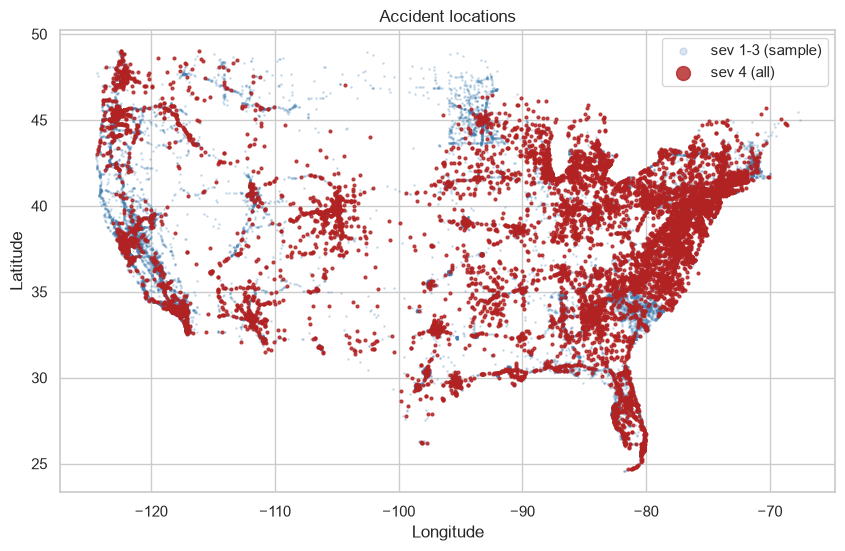

In [30]:
# Location: all severity-4 accidents plus a random sample of the rest
neg = df[df["target"] == 0].sample(min((df["target"] == 0).sum(), 100000), random_state=RANDOM_SEED)
pos = df[df["target"] == 1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(neg["Start_Lng"], neg["Start_Lat"], s=1, alpha=0.2, color="steelblue", label="sev 1-3 (sample)")
ax.scatter(pos["Start_Lng"], pos["Start_Lat"], s=4, alpha=0.8, color="firebrick", label="sev 4 (all)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_title("Accident locations")
ax.legend(markerscale=5); plt.show()

### Note
- Severity points for level 4 and level 1-3 are similarly spreadout in scatterbox. Level 1-3 accidents are more sparsely located as expected.
- All type of severities follow population and road networks. There are significant number of severity level 4 accidents near major cities and coastline hiding lower level accidents in scatterbox. Which indicates overplotting.
- There is a posibility to split data by regions and base judgement on them.

Distinct Weather_Condition values: 108


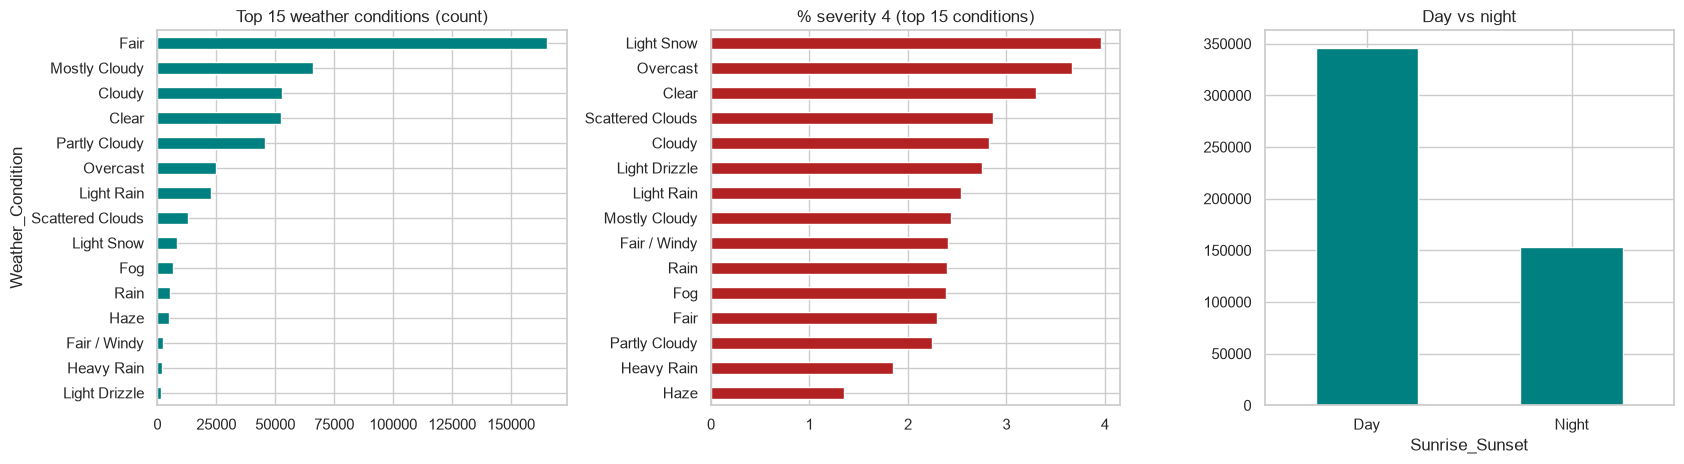

Top 5 Weather_Condition values cover 78.2% of non-missing rows
Top 10 Weather_Condition values cover 93.6% of non-missing rows
Top 15 Weather_Condition values cover 96.9% of non-missing rows
Top 20 Weather_Condition values cover 98.0% of non-missing rows
Categories with < 100 rows: 66


In [42]:
print("Distinct Weather_Condition values:", df["Weather_Condition"].nunique())
top = df["Weather_Condition"].value_counts().head(15).index
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
df["Weather_Condition"].value_counts().head(15).plot(kind="barh", ax=axes[0], color="teal")
axes[0].invert_yaxis(); axes[0].set_title("Top 15 weather conditions (count)")
(df[df["Weather_Condition"].isin(top)].groupby("Weather_Condition")["target"].mean() * 100).sort_values().plot(
    kind="barh", ax=axes[1], color="firebrick")
axes[1].set_title("% severity 4 (top 15 conditions)"); axes[1].set_ylabel("")
df["Sunrise_Sunset"].value_counts().plot(kind="bar", ax=axes[2], color="teal")
axes[2].set_title("Day vs night"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

wc = df["Weather_Condition"].value_counts(normalize=True).cumsum()
for k in (5, 10, 15, 20):
    print(f"Top {k} Weather_Condition values cover {wc.iloc[k-1]*100:.1f}% of non-missing rows")
print("Categories with < 100 rows:", (df["Weather_Condition"].value_counts() < 100).sum())

### Note:
- It is worth to mention that top 20 most frequent weather condition values cover 98% of non-missing rows. And if we remove categories that have less than a 100 records, we end up with 66 categories.
- Since there are 42 categories that have less than 100 records, it is better to remove them from our dataset.

In [41]:
bool_rates = pd.DataFrame({
    "pct_True": [df[c].mean() * 100 for c in BOOLEAN_FEATURES],
    "sev4_rate_if_True (%)": [df.loc[df[c] == True, "target"].mean() * 100 for c in BOOLEAN_FEATURES],
    "sev4_rate_if_False (%)": [df.loc[df[c] == False, "target"].mean() * 100 for c in BOOLEAN_FEATURES],
}, index=BOOLEAN_FEATURES).round(2)
bool_rates

,pct_True,sev4_rate_if_True (%),sev4_rate_if_False (%)
Amenity,1.27,1.96,2.66
Crossing,11.39,1.55,2.80
Junction,7.37,3.51,2.59
Railway,0.87,2.26,2.66
Station,2.63,1.58,2.68
Stop,2.78,2.66,2.65
Traffic_Signal,14.76,1.79,2.80


### Note:
- Traffic_Signal, Crossing, Junction are most common flags in our sample.
- However, percentages significantly drop with severity level 4 accidents. Especially with crossing and traffic signal cases.
- Rare flags like Railway might not be worth to consider due to rare appearance in dataset.

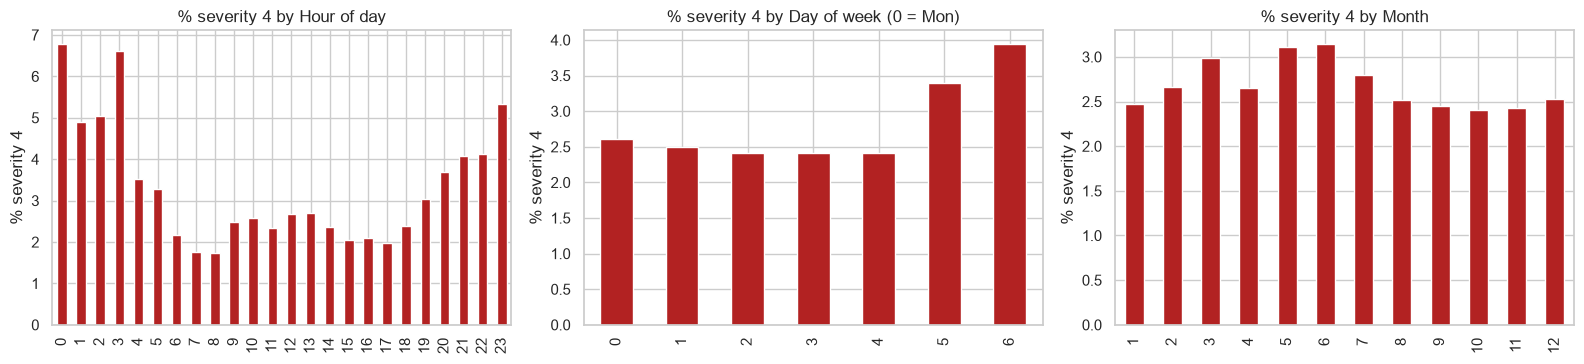

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, col, title in zip(axes, ["hour", "dayofweek", "month"], ["Hour of day", "Day of week (0 = Mon)", "Month"]):
    (df.groupby(col)["target"].mean() * 100).plot(kind="bar", ax=ax, color="firebrick")
    ax.set_title(f"% severity 4 by {title}"); ax.set_ylabel("% severity 4"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

### Note:
- Severity level 4 accidents are spreadout roughly evenly for every month with noticable increase in months 5-7 and month 3.
- Severity Level 4 accidents have significant increase in weekends, indicating higher risks for weekends which might be worth to include in our prediction model.
- Severity level 4 accidents have significant spike closer to the night. Especially between 23-3. And small drop in hours 7,8.

**Notes (write in your own words):**

- 

---
## 5. Correlation analysis
**Owner:** _TBD_

**Tasks**
- Correlation heatmap for numeric, boolean (as 0/1), time-derived features and the target.
- Highlight highly correlated feature pairs (e.g. |r| > 0.7), which matters later for feature selection.
- Correlation of each feature with the target.

In [ ]:
corr_df = df[NUMERIC_FEATURES + DERIVED_TIME_FEATURES].copy()
for c in BOOLEAN_FEATURES:
    corr_df[c] = df[c].astype(float)
corr_df["target"] = df["target"]

corr = corr_df.corr(numeric_only=True)
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=0.3)
plt.title("Correlation heatmap (Pearson)")
plt.tight_layout(); plt.show()

In [ ]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs.abs() > 0.7].sort_values(key=abs, ascending=False)
print("Highly correlated feature pairs (|r| > 0.7):")
display(strong.to_frame("r"))

target_corr = corr["target"].drop("target").sort_values(key=abs, ascending=False)
ax = target_corr.plot(kind="barh", figsize=(7, 6), color="steelblue")
ax.invert_yaxis(); ax.set_title("Correlation with target (severity 4)"); plt.tight_layout(); plt.show()

**Notes (write in your own words):**

- 

---
## 6. Key insights and challenges
**Owner:** whole team (write together after sections 1-5 are merged)

Summarise in your own words:
1. Class imbalance and how it changes across years
2. Missing data (which columns, how much, how we plan to handle it)
3. Leakage risks and which columns are excluded
4. Highly correlated or redundant features
5. Skewed features and outliers
6. What this means for preprocessing and modelling next

-